# Notebook 02: Data, catalogs and maps

**Goal (about 2 hours):** pull seismic data from EarthScope with ObsPy, work with the two tables that describe earthquakes (the *catalog*) and their arrival times (the *picks*), and map the July 2025 swarm and the stations on Rainier's topography.

Read along with:

- ObsPy's [Retrieving Data from Data Centers](https://docs.obspy.org/tutorial/code_snippets/retrieving_data_from_datacenters.html) and Seismo-Live's [06 FDSN](https://seismo-live.github.io/html/ObsPy/06_FDSN_wrapper.html) notebook (Krischer, CC BY-NC-SA 4.0).
- Seismo-Live's [05 Event metadata](https://seismo-live.github.io/html/ObsPy/05_Event_metadata_wrapper.html) for the vocabulary of events and picks.
- PNSN's [Mount Rainier page](https://pnsn.org/volcanoes/mount-rainier), which has a short section on the July 2025 swarm (20 minutes).

Data come from EarthScope (cite per [earthscope.org/how-to-cite](https://www.earthscope.org/how-to-cite/)), the catalog and picks from PNSN, and the topography from the USGS [3D Elevation Program](https://www.usgs.gov/3d-elevation-program).

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys, warnings
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


## 1. Pulling data from EarthScope

Nearly all permanent-network seismic data in the US are archived by EarthScope and served through standard **FDSN web services**, which ObsPy wraps in one `Client`. Every request says **who** (network and station), **what** (location and channel codes) and **when** (start and end time):

| field | example | meaning |
| --- | --- | --- |
| network | `UW`, `CC` | the operator: UW = Pacific Northwest Seismic Network, CC = Cascades Volcano Observatory |
| station | `STAR` | the site |
| location | `01` | distinguishes instruments at one site; use the wildcard `*` (STAR's is `01`, and assuming blank silently returns nothing) |
| channel | `EHZ`, `?H?` | band, instrument, orientation; `?H?` matches all seismic channels without the dozens of non-seismic ones some sites carry |

First ask what exists. `get_stations` returns an **Inventory** (network > station > channel). This is a live request; offline, the cell falls back to the station table shipped with the repo.

In [2]:
from obspy.clients.fdsn import Client
from obspy import UTCDateTime
ONLINE = True
try:
    client = Client(data.FDSN_URL, timeout=30)
    inv = client.get_stations(network="UW", station="STAR", level="channel",
                              starttime=UTCDateTime("2025-07-01"), endtime=UTCDateTime("2025-08-01"))
    print(inv)
except Exception as exc:
    ONLINE = False
    print("Offline (", type(exc).__name__, "). Using the repo's station table instead:")
    print(data.load_stations().query("station == 'STAR'"))

Inventory created at 2026-10-22T22:36:15.519700Z
	Created by: EarthScope WEB SERVICE: fdsnws-station | version: 1.1.58
		    https://service.earthscope.org/fdsnws/station/1/query?starttime=202...
	Sending institution: EarthScope (EarthScope)
	Contains:
		Networks (1):
			UW
		Stations (1):
			UW.STAR (St. Andrews Rock, Mt. Rainier, WA)
		Channels (4):
			UW.STAR.01.EHZ, UW.STAR.01.EHN, UW.STAR.01.EHE, UW.STAR.01.ELZ


Then ask for waveforms: the same who, what and when. The research pipeline takes 20 s per earthquake, from 5 s before the origin time to 15 s after.

In [3]:
cat = data.load_station_catalog("STAR")
row = cat[cat.evid == 61504668].iloc[0]          # the event from notebook 01
t0 = data.to_utc(row.start_time)                 # origin time - 5 s
if ONLINE:
    st = client.get_waveforms(network="UW", station="STAR", location="*", channel="?H?",
                              starttime=t0, endtime=t0 + 20)
    print(st)

3 Trace(s) in Stream:
UW.STAR.01.EHE | 2025-07-18T14:09:59.070000Z - 2025-07-18T14:10:19.070000Z | 100.0 Hz, 2001 samples
UW.STAR.01.EHN | 2025-07-18T14:09:59.070000Z - 2025-07-18T14:10:19.070000Z | 100.0 Hz, 2001 samples
UW.STAR.01.EHZ | 2025-07-18T14:09:59.070000Z - 2025-07-18T14:10:19.070000Z | 100.0 Hz, 2001 samples


That is all there is to it. In the lessons you will use `data.get_event_stream` instead, which makes exactly this request for one catalog row. The repo already ships most of the STAR windows in `data/waveforms/`, so it reads those when they are there and only goes to EarthScope when they are not. That keeps the lessons fast and runnable offline.

In [4]:
stream = data.get_event_stream("STAR", row)
print("source:", stream.source)
print(stream)

source: cache
3 Trace(s) in Stream:
UW.STAR.01.EHZ | 2025-07-18T14:09:59.070000Z - 2025-07-18T14:10:19.060000Z | 100.0 Hz, 2000 samples
UW.STAR.01.EHN | 2025-07-18T14:09:59.070000Z - 2025-07-18T14:10:19.060000Z | 100.0 Hz, 2000 samples
UW.STAR.01.EHE | 2025-07-18T14:09:59.070000Z - 2025-07-18T14:10:19.060000Z | 100.0 Hz, 2000 samples


### Which way do the components point?

A seismogram is only as good as the metadata that says which way each sensor points. Every channel's metadata includes its **azimuth** (degrees clockwise from north) and **dip** (degrees down from horizontal, so an upward vertical has dip -90). You can look them up for any station on the IRIS Metadata Aggregator, e.g. [ds.iris.edu/mda/UW/STAR](https://ds.iris.edu/mda/UW/STAR/), or with `get_stations(level="channel")`.

Metadata can be wrong. At STAR the two horizontals are **swapped**: the sensor labelled `EHN` points east and the one labelled `EHE` points north, although the archive still lists `EHN` at 0 and `EHE` at 90. For splitting, which is entirely about directions, that matters more than anything else in this notebook.

`get_event_stream` takes care of it. It looks up every channel's archived azimuth and dip (`data/catalog/channel_orientations.csv`, the same numbers MDA shows), overrides the ones known to be wrong (`data.ORIENTATION_FIXES`), and rotates the three components to true Z, N, E. Always get waveforms through it; never read the files and trust the channel names.

In [5]:
orient = data.load_orientations()
print("archived orientation of STAR's channels (location 01):")
print(orient.query("station == 'STAR' and location == '01'")[["channel", "start", "azimuth", "dip"]].to_string(index=False))
print("\nknown fixes:", data.ORIENTATION_FIXES)

raw = data.get_event_stream("STAR", row, correct_orientation=False)    # as archived: do not use for analysis
print("\ncorrected N is the archived EHE:", np.array_equal(stream.select(channel="EHN")[0].data, raw.select(channel="EHE")[0].data))
print("corrected E is the archived EHN:", np.array_equal(stream.select(channel="EHE")[0].data, raw.select(channel="EHN")[0].data))
print("noted in the trace:", stream[1].stats.processing[-1])

archived orientation of STAR's channels (location 01):
channel                     start  azimuth   dip
    EHE 2014-10-13 00:00:00+00:00     90.0   0.0
    EHN 2014-10-13 00:00:00+00:00      0.0   0.0
    EHZ 2014-10-13 00:00:00+00:00      0.0 -90.0
    ELZ 2014-10-13 00:00:00+00:00      0.0 -90.0

known fixes: {('UW', 'STAR', '01', 'EHN'): (90.0, 0.0), ('UW', 'STAR', '01', 'EHE'): (0.0, 0.0)}

corrected N is the archived EHE: True
corrected E is the archived EHN: True
noted in the trace: orient_zne: EHZ az=0 dip=-90 (metadata), EHN az=90 dip=0 (fix), EHE az=0 dip=0 (fix)


## 2. The event catalog

An earthquake catalog is a table: one row per earthquake with origin time, latitude, longitude, depth and magnitude. Ours is a PNSN export for the Rainier area. The locations were computed by PNSN from arrival times and a simple layered velocity model; they carry errors of hundreds of metres to a few km, which we will come back to.

Catalogs can be pulled the same way as waveforms (`Client("USGS").get_events(...)` returns a catalog from USGS ComCat), but catalogs are revised for months after a swarm, so the lessons use a frozen PNSN export: `data/catalog/rainier_events.csv`.

In [6]:
ev = data.load_events()
print(len(ev), "events;", ev.time.min().date(), "to", ev.time.max().date())
ev[["evid", "time", "lat", "lon", "depth", "magnitude"]].head()

1378 events; 2025-07-08 to 2025-08-29


,evid,time,lat,lon,depth,magnitude
0,62134047,2025-07-08 02:57:36.649997711+00:00,46.846500,-121.770167,-1.85,0.46
1,62134077,2025-07-08 05:14:01.960000038+00:00,46.849500,-121.761500,-1.02,0.34
2,62134102,2025-07-08 08:39:50.009998322+00:00,46.851333,-121.762000,-0.33,0.28
3,61504508,2025-07-08 08:40:21.079999924+00:00,46.853000,-121.764500,0.52,0.02
4,62134107,2025-07-08 08:45:38.549999237+00:00,46.850167,-121.759333,-0.28,1.46


Depth convention (easy to get wrong): kilometres **relative to sea level, positive down**. Rainier's summit is 4.39 km above sea level, so an earthquake 1 km below the summit has depth about -3.4. Negative depths are normal here.

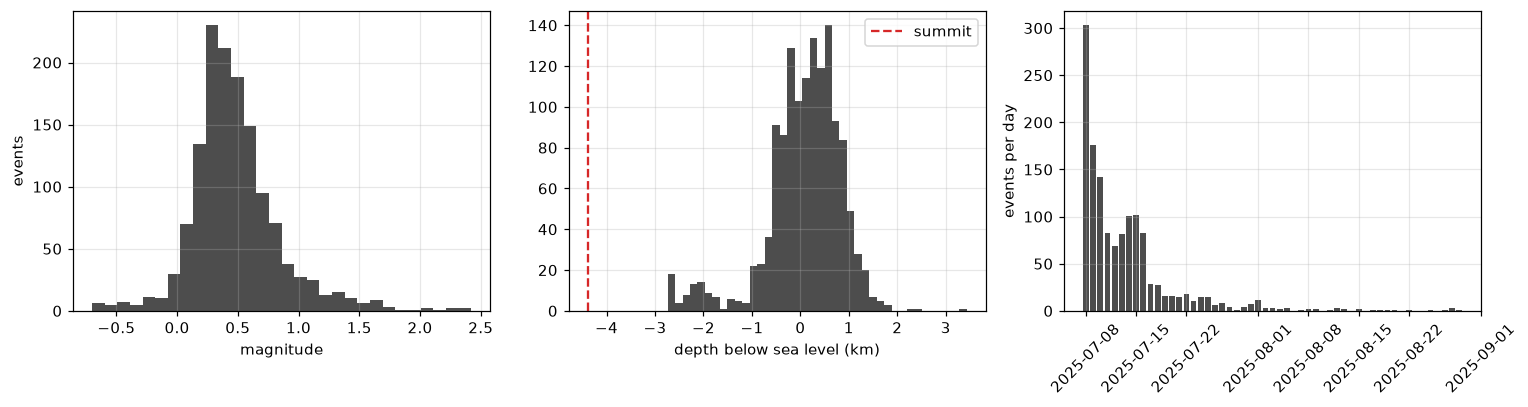

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(ev.magnitude.dropna(), bins=30, color="0.3"); axes[0].set_xlabel("magnitude"); axes[0].set_ylabel("events")
axes[1].hist(ev.depth, bins=40, color="0.3"); axes[1].set_xlabel("depth below sea level (km)")
axes[1].axvline(-4.392, color="tab:red", ls="--", label="summit"); axes[1].legend()
daily = ev.set_index("time").resample("D").size()
axes[2].bar(daily.index, daily.values, color="0.3"); axes[2].set_ylabel("events per day")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()

Three things the histograms tell you: most events are tiny (magnitude below 1; a magnitude-0 earthquake releases about as much energy as a hand grenade), they are shallow and clustered near the summit, and the whole swarm happens in about two weeks starting July 8, 2025 with most of it in the first few days.

## 3. Topography

The repo ships a digital elevation model (DEM) of the volcano from the USGS 3D Elevation Program: a grid of elevations in metres, 2 arc-seconds (about 60 m) per pixel, covering about 45 by 45 km around the summit. `data.load_topography()` reads it (and downloads it from the USGS elevation service if the file is missing). It returns the grid and its **extent**, the longitude and latitude of its edges, which is what `imshow` needs to put it on map coordinates.

grid: (720, 1080) rows x columns; 317 to 4385 m
extent [lon_min, lon_max, lat_min, lat_max]: [-122.06, -121.46, 46.65, 47.05]


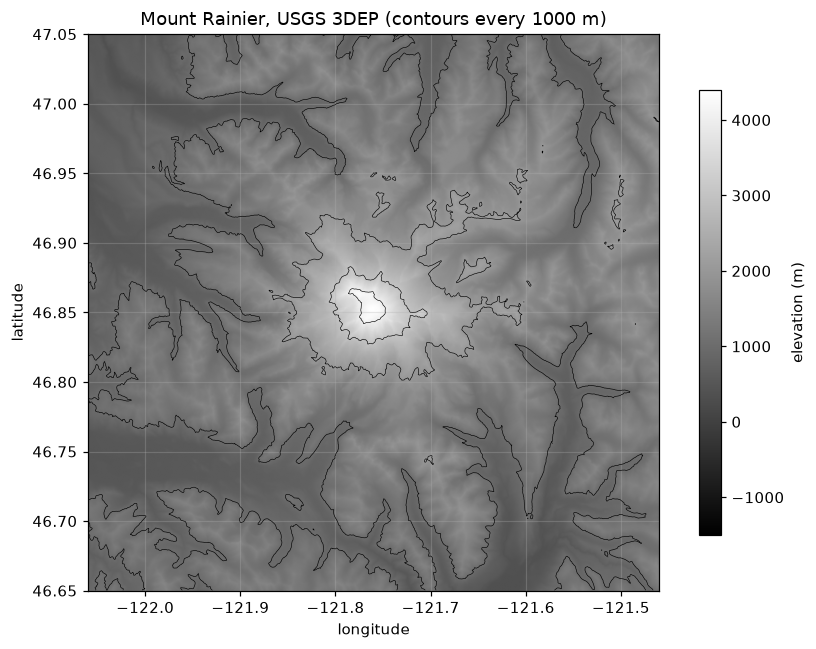

In [8]:
elev, extent = data.load_topography()
print("grid:", elev.shape, "rows x columns;", f"{elev.min():.0f} to {elev.max():.0f} m")
print("extent [lon_min, lon_max, lat_min, lat_max]:", [round(x, 2) for x in extent])

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(elev, extent=extent, cmap="gray", vmin=-1500, vmax=4400)
ax.contour(elev, levels=np.arange(1000, 4500, 1000), extent=extent, origin="upper", colors="k", linewidths=0.4)
ax.set_aspect(1 / np.cos(np.deg2rad(46.85)))
fig.colorbar(im, ax=ax, label="elevation (m)", shrink=0.8)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("Mount Rainier, USGS 3DEP (contours every 1000 m)")
plt.tight_layout()

Two details. `vmin=-1500` starts the grey scale below sea level, so the lowest valleys (about 300 m) are drawn mid-grey rather than black and the contours stay visible. And `origin="upper"` on the contour call matters because row 0 of the grid is the *northern* edge, the way images are stored; `imshow` assumes that already.

## 4. Map it

A map is a scatter plot of longitude against latitude on top of the topography. A degree of longitude is shorter than a degree of latitude at 47 N by a factor cos(47 deg), about 0.68, so we set the aspect ratio to keep distances honest. Stations are triangles, the convention in seismology.

For a background that shows the shape of the mountain without fighting with the data, shade the DEM as if lit from the north-west (`LightSource`). The function below draws that background on any axes and limits, so the same code makes the regional map and the summit zoom.

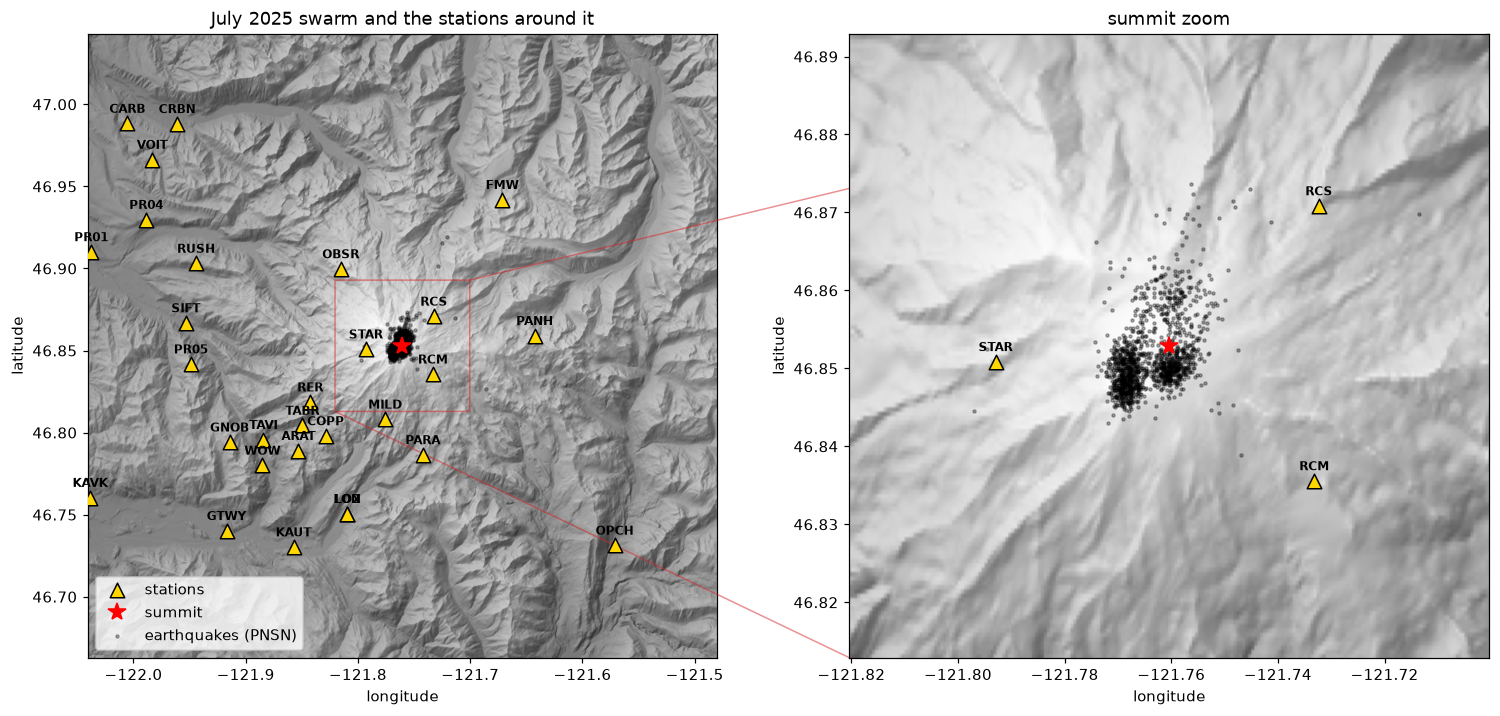

In [9]:
from matplotlib.colors import LightSource

summit = (46.8529, -121.7604)
sta = data.load_stations()
# metres per pixel, so the shading's slopes are real slopes
dx = (extent[1] - extent[0]) / elev.shape[1] * 111.32e3 * np.cos(np.deg2rad(summit[0]))
dy = (extent[3] - extent[2]) / elev.shape[0] * 111.32e3
relief = LightSource(azdeg=315, altdeg=45).shade(elev, cmap=plt.cm.gray, vmin=-2000, vmax=5000,
                                                 blend_mode="soft", vert_exag=2, dx=dx, dy=dy)

def basemap(ax, half_width_lon, half_width_lat, labels=True):
    """Shaded relief, stations and the summit around Rainier, within the given half-widths in degrees."""
    ax.imshow(relief, extent=extent, zorder=0)
    lon_lim = (summit[1] - half_width_lon, summit[1] + half_width_lon)
    lat_lim = (summit[0] - half_width_lat, summit[0] + half_width_lat)
    inside = sta.lon.between(*lon_lim) & sta.lat.between(*lat_lim)
    ax.scatter(sta.lon[inside], sta.lat[inside], marker="^", s=90, c="#FFD700", edgecolor="k", zorder=5, label="stations")
    if labels:
        for _, s in sta[inside].iterrows():
            ax.annotate(s.station, (s.lon, s.lat), xytext=(0, 7), textcoords="offset points",
                        ha="center", fontsize=8, weight="bold", zorder=6)
    ax.plot(summit[1], summit[0], "r*", ms=12, zorder=6, label="summit")
    ax.set_xlim(lon_lim); ax.set_ylim(lat_lim)
    ax.set_aspect(1 / np.cos(np.deg2rad(summit[0])))
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
basemap(axes[0], 0.28, 0.19)
basemap(axes[1], 0.06, 0.04)
for ax in axes:
    ax.scatter(ev.lon, ev.lat, s=4, c="k", alpha=0.3, zorder=4, label="earthquakes (PNSN)")
axes[0].indicate_inset_zoom(axes[1], edgecolor="tab:red")
axes[0].legend(loc="lower left"); axes[0].set_title("July 2025 swarm and the stations around it")
axes[1].set_title("summit zoom")
plt.tight_layout()

The swarm is a tight cloud about 2 km across: two dense lobes less than 1 km apart, just south and south-west of the summit, with a sparser spread to the north. STAR is about 2.5 km **west** of the summit and 1 km below it, so almost every swarm earthquake is to its east. RCM (Camp Muir) is about 3 km south-east of the swarm and RCS about 3 km north-east. (LON and LO2 are the same site, so their labels overlap.) The ring of stations farther out sees the swarm at a shallower angle, which matters a lot for splitting, as notebook 04 explains.

## 5. Picks

A **pick** is the time an analyst (or an algorithm) marked a wave arrival on one station's record. The catalog we use for splitting is a table of (earthquake, station) pairs that have **both** a P and an S pick, each with a quality score from 0 to 1. The `_strict` catalog keeps only pairs where both scores are at least 0.75. That is the first filtering decision in the whole project and it is worth remembering: *we only ever measure earthquakes that a human was confident about.*

In [10]:
print(len(cat), "earthquake-station pairs at STAR with reviewed P and S picks")
cat[["evid", "origin_time", "p_time", "p_quality", "s_time", "s_quality", "event_magnitude", "event_depth"]].head()

1196 earthquake-station pairs at STAR with reviewed P and S picks


,evid,origin_time,p_time,p_quality,s_time,s_quality,event_magnitude,event_depth
0,61504363,2025-07-08 15:24:37.709999084+00:00,2025-07-08 15:24:38.421168804+00:00,1.0,2025-07-08 15:24:38.989881754+00:00,1.00,-0.44,0.45
1,61504373,2025-07-08 15:38:45.819999695+00:00,2025-07-08 15:38:46.439848900+00:00,1.0,2025-07-08 15:38:47.008554220+00:00,0.75,0.31,0.03
2,61504388,2025-07-08 15:47:51.469997406+00:00,2025-07-08 15:47:52.119999886+00:00,1.0,2025-07-08 15:47:52.719038963+00:00,1.00,0.36,0.26
3,61504393,2025-07-08 15:50:27.059999704+00:00,2025-07-08 15:50:27.759302855+00:00,1.0,2025-07-08 15:50:28.331223011+00:00,0.75,-0.53,0.13
4,61504398,2025-07-08 15:50:56.389999390+00:00,2025-07-08 15:50:57.039684772+00:00,1.0,2025-07-08 15:50:57.589113712+00:00,0.75,-0.08,-0.26


median S-P at STAR: 0.60 s


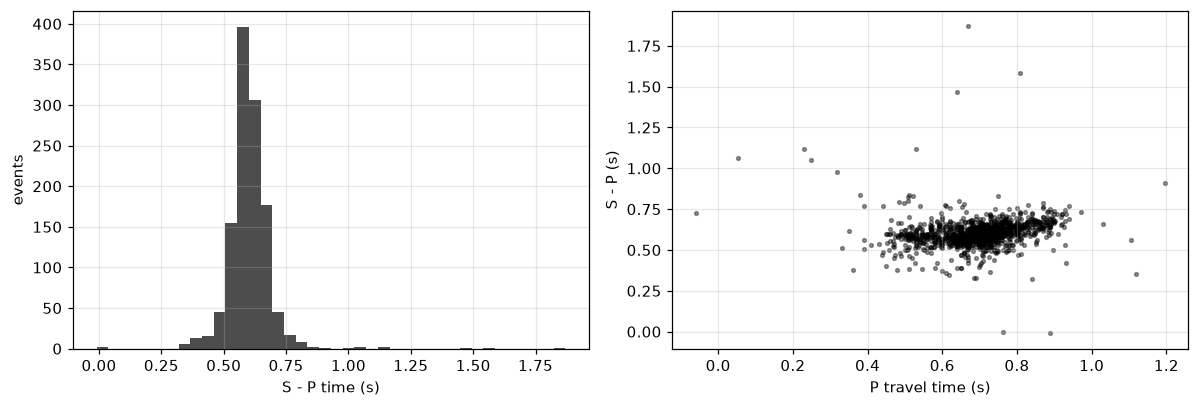

In [11]:
cat["sp_s"] = (cat.s_time - cat.p_time).dt.total_seconds()
cat["p_minus_origin"] = (cat.p_time - cat.origin_time).dt.total_seconds()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(cat.sp_s, bins=40, color="0.3"); axes[0].set_xlabel("S - P time (s)"); axes[0].set_ylabel("events")
axes[1].scatter(cat.p_minus_origin, cat.sp_s, s=6, c="k", alpha=0.4)
axes[1].set_xlabel("P travel time (s)"); axes[1].set_ylabel("S - P (s)")
plt.tight_layout()
print(f"median S-P at STAR: {cat.sp_s.median():.2f} s")

The S-P times cluster around 0.6 s: these earthquakes are a few km from STAR. The right panel should be close to a straight line: S-P equals P travel time times (Vp/Vs - 1), so its slope is a crude estimate of the velocity ratio. Scatter off the line is pick error plus location error plus real structure. Hold that thought for the uncertainty notebooks.

## 6. Geometry: back azimuth and distance

For each (earthquake, station) pair we need the **back azimuth**, the compass direction from the station to the earthquake, and the distance. ObsPy's `gps2dist_azimuth` does the spherical geometry. Mind the order of what it returns: `gps2dist_azimuth(lat_a, lon_a, lat_b, lon_b)` gives the distance in metres, the azimuth from a to b, and the azimuth from b to a. With the station as a and the earthquake as b, the back azimuth is the **second** value.

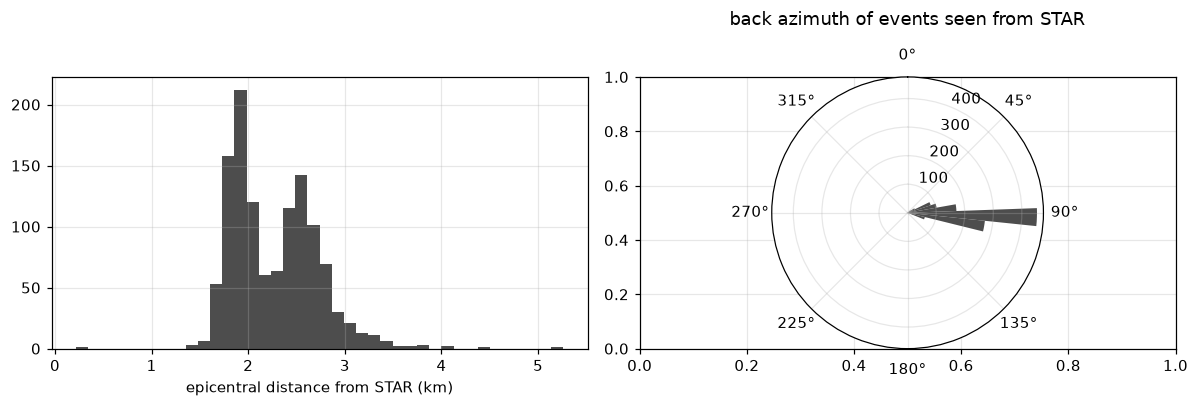

In [12]:
from obspy.geodetics import gps2dist_azimuth
lat, lon, elev = data.station_coords("STAR")
geo = [gps2dist_azimuth(lat, lon, r.event_lat, r.event_lon) for _, r in cat.iterrows()]
cat["dist_km"] = [g[0] / 1000 for g in geo]
cat["baz"] = [g[1] for g in geo]       # azimuth from station (a) to event (b)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(cat.dist_km, bins=40, color="0.3"); axes[0].set_xlabel("epicentral distance from STAR (km)")
ax = plt.subplot(1, 2, 2, projection="polar"); ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.hist(np.deg2rad(cat.baz), bins=36, color="0.3"); ax.set_title("back azimuth of events seen from STAR", pad=15)
plt.tight_layout()

Almost everything arrives from one narrow range of back azimuths (the swarm is small and sits in one direction). That is important and slightly unfortunate: with all rays coming from the same direction we cannot separate "the rock is anisotropic" from "something about this one ray path"; stations with a spread of back azimuths are more convincing. Notebook 07 returns to this.

## 7. Exercises

1. If online: ask EarthScope for **every** UW and CC station within 20 km of the summit that was operating in July 2025 (`client.get_stations` with `latitude`, `longitude` and `maxradius` in degrees; `obspy.geodetics.kilometers2degrees` converts). Put them on the map with `basemap`. Which ones are not in the repo's station table, and why might the research catalog not use them?
2. Make the summit-zoom map again with the earthquakes coloured by day (`ev.time.dt.dayofyear`). Does the swarm move with time?
3. Fit a straight line to the P-travel-time versus S-P plot (`np.polyfit`) and estimate Vp/Vs. Compare with the 1.73 assumed in the research repo's velocity model.
4. Repeat section 6 for RCM: its picks are in `data/catalog/rainier_catalog_strict.csv` (filter it by station). Is the back-azimuth distribution wider than STAR's?

Next: `03_filtering_spectra_snr.ipynb`.

## 8. Example solutions

One way to do each exercise. Try them yourself first.

### Exercise 1: every station near the summit

26 stations within 20 km, 24 of them in the repo's table
network station      lat        lon    channels  in_repo
     CC    TACK 46.80334 -121.84436         HDF    False
     UW    LON9 46.75060 -121.80960 HAX,HAY,HKI    False


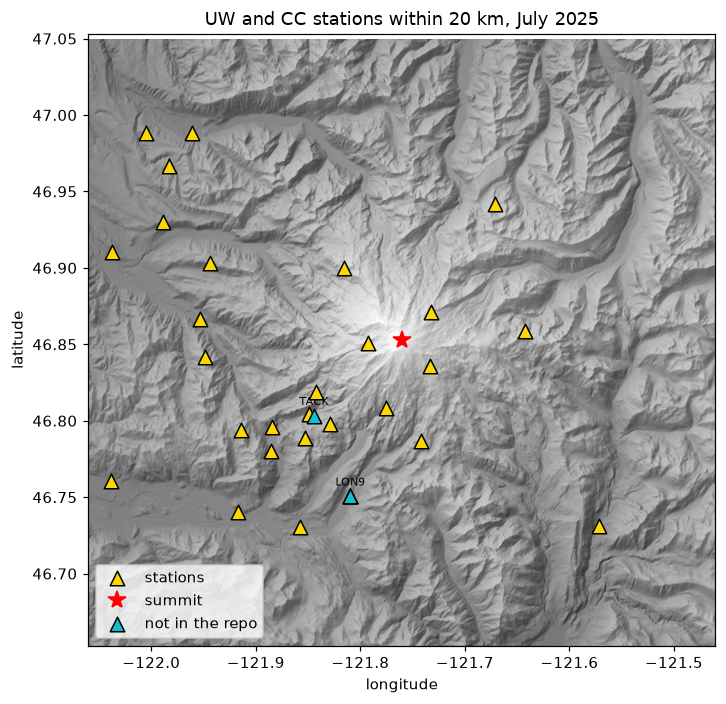

In [13]:
from obspy.geodetics import kilometers2degrees

if ONLINE:
    inv_all = client.get_stations(network="UW,CC", latitude=summit[0], longitude=summit[1],
                                  maxradius=kilometers2degrees(20), level="channel",
                                  starttime=UTCDateTime("2025-07-01"), endtime=UTCDateTime("2025-08-01"))
    near = pd.DataFrame([{"network": net.code, "station": s.code, "lat": s.latitude, "lon": s.longitude,
                          "channels": ",".join(sorted({c.code for c in s.channels}))}
                         for net in inv_all for s in net])
    near["in_repo"] = near.station.isin(sta.station)
    print(f"{len(near)} stations within 20 km, {near.in_repo.sum()} of them in the repo's table")
    print(near[~near.in_repo].to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 6.5))
    basemap(ax, 0.3, 0.2, labels=False)
    new = near[~near.in_repo]
    ax.scatter(new.lon, new.lat, marker="^", s=90, c="tab:cyan", edgecolor="k", zorder=5, label="not in the repo")
    for _, s in new.iterrows():
        ax.annotate(s.station, (s.lon, s.lat), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7)
    ax.legend(loc="lower left"); ax.set_title("UW and CC stations within 20 km, July 2025")
    plt.tight_layout()
else:
    print("Offline: run this cell when you have a connection.")

Two stations within 20 km are missing from the repo's table, and the channel codes say why: neither records ground motion. **TACK** has only `HDF`, an infrasound (air-pressure) sensor (instrument code `D` = pressure). **LON9** has `HAX`, `HAY` and `HKI`: a tiltmeter (`A`) and a temperature channel (`K`) at the LON site. Without a seismometer there are no P and S picks, so they never enter a splitting catalog.

The reverse is also true: the repo's table has stations far beyond 20 km (MOX, WINDI, ...). It lists every station that has at least one pick in the research catalog, not every station near the volcano. *Metadata is not data*: an Inventory tells you what is installed, not what recorded the events you care about.

### Exercise 2: does the swarm move?

weeks are labelled by their last day (Sunday)


                           events  median lat  median lon  median depth (km)
time                                                                        
2025-07-13 00:00:00+00:00     855     46.8503   -121.7643               0.15
2025-07-20 00:00:00+00:00     373     46.8490   -121.7675               0.21
2025-07-27 00:00:00+00:00      87     46.8512   -121.7595               0.34
2025-08-03 00:00:00+00:00      34     46.8530   -121.7567               0.24
2025-08-10 00:00:00+00:00      10     46.8579   -121.7682               0.75
2025-08-17 00:00:00+00:00       9     46.8545   -121.7628              -0.54
2025-08-24 00:00:00+00:00       4     46.8610   -121.7523              -1.30
2025-08-31 00:00:00+00:00       6     46.8637   -121.7548              -0.58


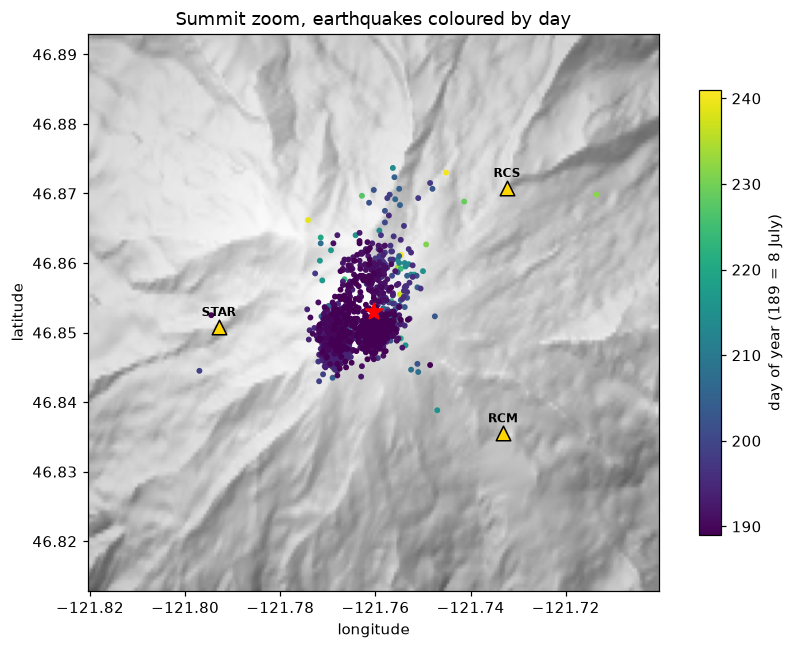

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
basemap(ax, 0.06, 0.04)
order = ev.sort_values("time", ascending=False)        # draw the early events on top
pts = ax.scatter(order.lon, order.lat, c=order.time.dt.dayofyear, cmap="viridis", s=8, zorder=4)
cb = fig.colorbar(pts, ax=ax, shrink=0.8); cb.set_label("day of year (189 = 8 July)")
ax.set_title("Summit zoom, earthquakes coloured by day")
plt.tight_layout()

# the same question in numbers: the median position each week
weekly = ev.set_index("time")[["lat", "lon", "depth"]].resample("W").agg(["median", "size"])
weekly = weekly[weekly[("lat", "size")] > 0]
print("weeks are labelled by their last day (Sunday)")
print(pd.DataFrame({"events": weekly[("lat", "size")], "median lat": weekly[("lat", "median")].round(4),
                    "median lon": weekly[("lon", "median")].round(4),
                    "median depth (km)": weekly[("depth", "median")].round(2)}).to_string())

Within the main swarm (the dark colours, the first two weeks) there is no obvious migration: the same two lobes are active from start to finish, and the weekly median position moves by less than 0.005 degrees (about 400 m), less than the location errors. The late, sparse events (August, green to yellow) are scattered more to the north and north-east, and the last three weeks have median depths *above* sea level (-0.5 to -1.3 km) where July's were 0.15 to 0.34 km below. With 4 to 10 events a week and location errors of hundreds of metres, that is a hint, not a result.

For comparison, Shelly et al. (2013) found the 2009 swarm migrating outward, but only after relocating the events with waveform cross-correlation. The unrelocated catalog may simply be too blurry to show it, which is why relocation is step 1 of the research plan.

### Exercise 3: Vp/Vs from the picks

S-P = (Vp/Vs - 1) × (P travel time), so the slope of the line is Vp/Vs - 1. Fit it, and also fit a line forced through the origin, which is what the physics says (zero travel time, zero S-P).

free fit:           S-P = 0.088 * t_P + +0.542 s  ->  Vp/Vs = 1.09
through the origin: S-P = 0.851 * t_P            ->  Vp/Vs = 1.85


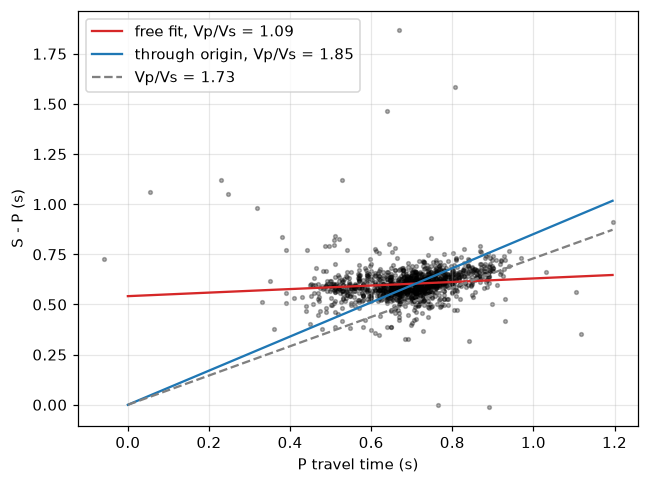

In [15]:
x, y = cat.p_minus_origin.to_numpy(), cat.sp_s.to_numpy()
slope, intercept = np.polyfit(x, y, 1)
slope0 = np.sum(x * y) / np.sum(x * x)                 # least squares through the origin
print(f"free fit:           S-P = {slope:.3f} * t_P + {intercept:+.3f} s  ->  Vp/Vs = {1 + slope:.2f}")
print(f"through the origin: S-P = {slope0:.3f} * t_P            ->  Vp/Vs = {1 + slope0:.2f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(x, y, s=6, c="k", alpha=0.3)
xx = np.linspace(0, x.max(), 50)
ax.plot(xx, slope * xx + intercept, "tab:red", label=f"free fit, Vp/Vs = {1 + slope:.2f}")
ax.plot(xx, slope0 * xx, "tab:blue", label=f"through origin, Vp/Vs = {1 + slope0:.2f}")
ax.plot(xx, 0.73 * xx, "0.5", ls="--", label="Vp/Vs = 1.73")
ax.set_xlabel("P travel time (s)"); ax.set_ylabel("S - P (s)"); ax.legend()
plt.tight_layout()

The free fit says Vp/Vs = 1.09, which is physically impossible (rocks have Vp/Vs above about 1.5), and its intercept says there are 0.54 s of S-P at zero distance. Two things went wrong, and both are worth remembering:

- **The x values span a narrow range.** Every event is about the same distance from STAR, so the P travel times bunch between about 0.5 and 0.9 s, and the slope is poorly pinned.
- **The error is in x, not y.** P travel time is the pick minus the *origin time*, and the origin time is an estimate with its own error. S-P does not involve the origin time at all. Least squares assumes the error is in y; noise in x drags the slope towards zero (*regression dilution*), and the intercept absorbs the rest.

Forcing the line through the origin, which the physics requires, gives Vp/Vs = 1.85, above the 1.73 of the research velocity model. That could be real (fractured, fluid-filled volcanic rock can have a high Vp/Vs) or a bias in the origin times. The way to tell is a **Wadati diagram**: for one earthquake, plot S-P against the P *arrival time* at many stations. The slope is still Vp/Vs - 1, and the origin time drops out. Note also the handful of points with P travel times near zero or negative, a P pick at or before the origin time: those rows have a bad pick or a bad origin time.

### Exercise 4: back azimuths at RCM

STAR: median distance 2.2 km, back azimuth 5th to 95th percentile 66 to 105 deg
RCM: median distance 3.0 km, back azimuth 5th to 95th percentile 293 to 326 deg


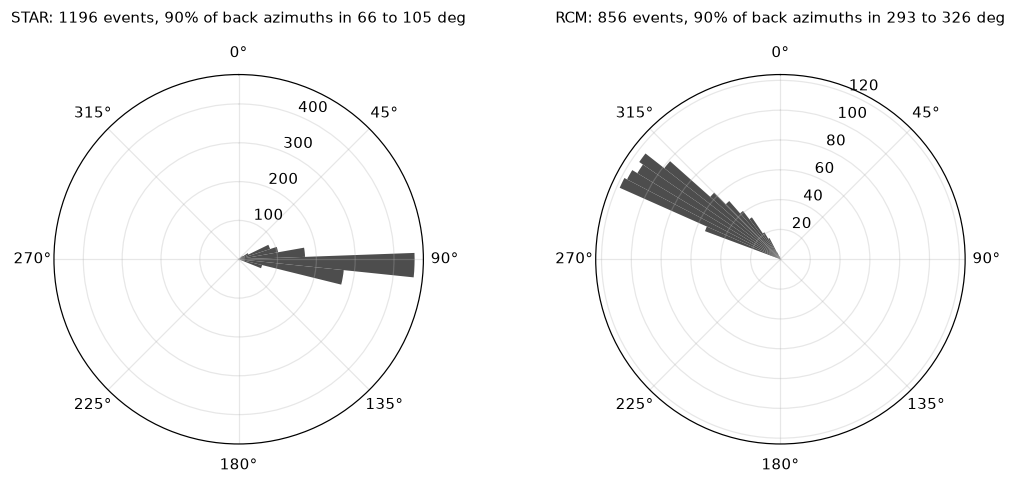

In [16]:
strict = pd.read_csv(paths.STRICT_CATALOG_CSV)
geo_by_station = {}
for code_ in ["STAR", "RCM"]:
    picks = strict[strict.station == code_]
    s_lat, s_lon, _ = data.station_coords(code_)
    geo_by_station[code_] = pd.DataFrame(
        [gps2dist_azimuth(s_lat, s_lon, la, lo) for la, lo in zip(picks.event_lat, picks.event_lon)],
        columns=["dist_m", "baz", "az_event_to_station"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), subplot_kw={"projection": "polar"})
for ax, (code_, g) in zip(axes, geo_by_station.items()):
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.hist(np.deg2rad(g.baz), bins=36, color="0.3")
    lo, hi = np.percentile(g.baz, [5, 95])
    ax.set_title(f"{code_}: {len(g)} events, 90% of back azimuths in {lo:.0f} to {hi:.0f} deg", pad=15, fontsize=10)
    print(f"{code_}: median distance {g.dist_m.median() / 1e3:.1f} km, back azimuth 5th to 95th percentile {lo:.0f} to {hi:.0f} deg")
plt.tight_layout()

No. RCM's back azimuths span about 33 degrees (5th to 95th percentile, 293 to 326: the swarm is north-west of RCM), STAR's about 39 (66 to 105: the swarm is east of STAR). Both stations are 2 to 3 km from a swarm about 2 km across, so each sees it through a narrow window.

But the two stations look at the swarm from nearly **opposite sides**, about 180 degrees apart, and that is the useful part: combining stations gives the spread of directions that no single station near this swarm can. Note the STAR numbers agree with the research results (median back azimuth about 91 degrees in `results/sws_star_strict_results.csv`), which is a good check that the station-to-event direction was computed the right way round.